<a href="https://colab.research.google.com/github/leroymakitaloubaki-web/license-plate-recognition-yolov8/blob/main/plaques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cellule 1 — Installation des dépendances
!pip install ultralytics easyocr opencv-python-headless matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 13.6 MB/s eta 0:00:00


In [ ]:
# Cellule 2 — Montage Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Chemins du dataset
DATASET_PATH = '/content/drive/MyDrive/plaque_voiture/archive'
TRAIN_PATH   = f'{DATASET_PATH}/train'
VALID_PATH   = f'{DATASET_PATH}/valid'
TEST_PATH    = f'{DATASET_PATH}/test'

print("Chemins configurés :")
print(f"  Train : {TRAIN_PATH}")
print(f"  Valid : {VALID_PATH}")
print(f"  Test  : {TEST_PATH}")

Mounted at /content/drive
Chemins configurés :
  Train : /content/drive/MyDrive/plaque_voiture/archive/train
  Valid : /content/drive/MyDrive/plaque_voiture/archive/valid
  Test  : /content/drive/MyDrive/plaque_voiture/archive/test


In [ ]:
# Cellule 3 — Vérification de la structure du dataset
import os

for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(DATASET_PATH, split, 'images')
    lbl_dir = os.path.join(DATASET_PATH, split, 'labels')

    n_imgs = len(os.listdir(img_dir)) if os.path.exists(img_dir) else 0
    n_lbls = len(os.listdir(lbl_dir)) if os.path.exists(lbl_dir) else 0

    print(f"{split:>5} → images : {n_imgs:>5}  |  labels : {n_lbls:>5}")

print("\nStructure OK !" if n_imgs > 0 else "\nProblème de chemin, vérifie DATASET_PATH")

train → images :  7057  |  labels :  7057
valid → images :  2048  |  labels :  2048
 test → images :  1020  |  labels :  1020

Structure OK !


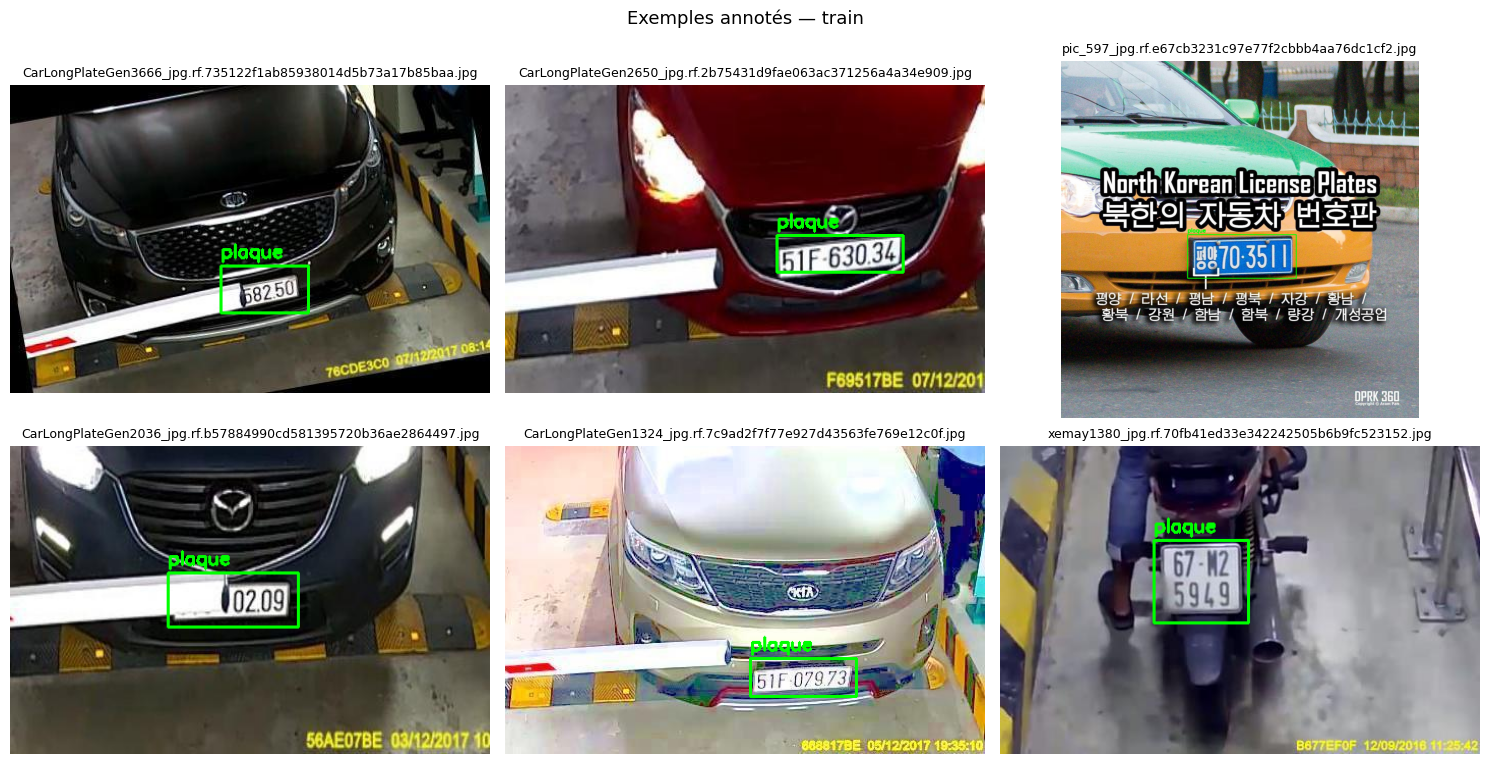

In [ ]:
# Cellule 4 — Visualisation de quelques images annotées
import cv2
import matplotlib.pyplot as plt
import numpy as np
import random
import os

def afficher_annotations(split='train', n=6):
    img_dir = os.path.join(DATASET_PATH, split, 'images')
    lbl_dir = os.path.join(DATASET_PATH, split, 'labels')

    images = [f for f in os.listdir(img_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]
    echantillon = random.sample(images, min(n, len(images)))

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for i, nom in enumerate(echantillon):
        # Chargement image
        img = cv2.imread(os.path.join(img_dir, nom))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        # Chargement label YOLO (format : classe cx cy cw ch normalisés)
        lbl_path = os.path.join(lbl_dir, nom.rsplit('.', 1)[0] + '.txt')
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for ligne in f.readlines():
                    _, cx, cy, bw, bh = map(float, ligne.strip().split())
                    x1 = int((cx - bw/2) * w)
                    y1 = int((cy - bh/2) * h)
                    x2 = int((cx + bw/2) * w)
                    y2 = int((cy + bh/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    cv2.putText(img, 'plaque', (x1, y1-8),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

        axes[i].imshow(img)
        axes[i].set_title(nom, fontsize=9)
        axes[i].axis('off')

    plt.suptitle(f'Exemples annotés — {split}', fontsize=13)
    plt.tight_layout()
    plt.show()

afficher_annotations('train', n=6)

In [ ]:
# Cellule 5 — Création du fichier data.yaml pour YOLOv8
import yaml

data = {
    'path'  : DATASET_PATH,
    'train' : 'train/images',
    'val'   : 'valid/images',
    'test'  : 'test/images',
    'nc'    : 1,
    'names' : ['plaque']
}

yaml_path = '/content/data.yaml'

with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False, allow_unicode=True)

print("Contenu du data.yaml :")
print("----------------------")
with open(yaml_path, 'r') as f:
    print(f.read())

Contenu du data.yaml :
----------------------
names:
- plaque
nc: 1
path: /content/drive/MyDrive/plaque_voiture/archive
test: test/images
train: train/images
val: valid/images



In [ ]:
# Cellule 6 — Copie locale + Entraînement YOLOv8
!pip install ultralytics -q

import shutil, os, yaml
from ultralytics import YOLO

# Étape 1 — Copie du dataset en local (plus rapide)
print("Copie du dataset en local...")
if not os.path.exists('/content/dataset'):
    shutil.copytree(DATASET_PATH, '/content/dataset')
    print("Copie terminée !")
else:
    print("Dataset déjà en local ✅")

# Étape 2 — Création du yaml local
data = {
    'path'  : '/content/dataset',
    'train' : 'train/images',
    'val'   : 'valid/images',
    'test'  : 'test/images',
    'nc'    : 1,
    'names' : ['plaque']
}
with open('/content/data_local.yaml', 'w') as f:
    yaml.dump(data, f, default_flow_style=False)
print("Yaml local créé ✅")

# Étape 3 — Entraînement
model = YOLO('yolov8n.pt')

results = model.train(
    data    = '/content/data_local.yaml',
    epochs  = 50,
    imgsz   = 640,
    batch   = 16,
    patience= 10,
    device  = '0',
    project = '/content/drive/MyDrive/plaque_voiture',
    name    = 'entrainement_v1',
    exist_ok= True
)

print("Entraînement terminé !")

Copie du dataset en local...
Copie terminée !
Yaml local créé ✅
Ultralytics 8.4.69 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=entrainement_v1, nbs=64, nms=False, opset=None,

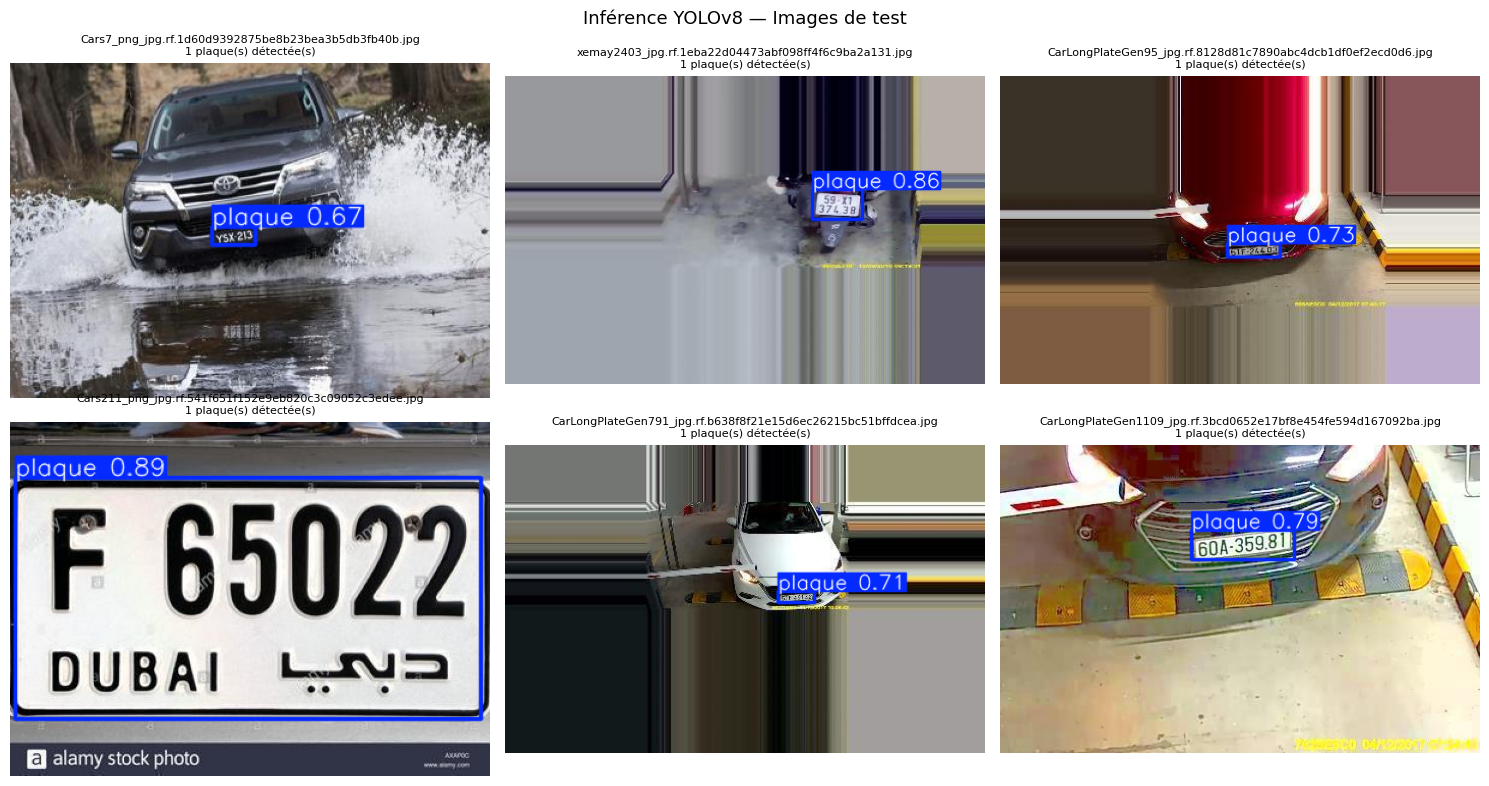

In [ ]:
# Cellule 7 — Inférence sur images de test
import cv2
import matplotlib.pyplot as plt
import os
import random
from ultralytics import YOLO

# Chargement du meilleur modèle
MODEL_PATH = '/content/drive/MyDrive/plaque_voiture/entrainement_v1/weights/best.pt'
model = YOLO(MODEL_PATH)

# Dossier des images de test
TEST_IMG_DIR = '/content/dataset/test/images'

# Sélection aléatoire de 6 images de test
images = [f for f in os.listdir(TEST_IMG_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]
echantillon = random.sample(images, min(6, len(images)))

# Affichage
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, nom in enumerate(echantillon):
    img_path = os.path.join(TEST_IMG_DIR, nom)

    # Inférence YOLOv8
    results = model(img_path, conf=0.5, verbose=False)

    # Image annotée par YOLO
    img_annotee = results[0].plot()
    img_annotee = cv2.cvtColor(img_annotee, cv2.COLOR_BGR2RGB)

    # Nombre de plaques détectées
    n_detections = len(results[0].boxes)

    axes[i].imshow(img_annotee)
    axes[i].set_title(f'{nom}\n{n_detections} plaque(s) détectée(s)', fontsize=8)
    axes[i].axis('off')

plt.suptitle('Inférence YOLOv8 — Images de test', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
# Cellule 8 — Détection + OCR sur images de test
import cv2
import matplotlib.pyplot as plt
import easyocr
import os
import random
from ultralytics import YOLO

# Chargement modèle + OCR
MODEL_PATH = '/content/drive/MyDrive/plaque_voiture/entrainement_v1/weights/best.pt'
model  = YOLO(MODEL_PATH)
reader = easyocr.Reader(['en'], gpu=True)

# Dossier test
TEST_IMG_DIR = '/content/dataset/test/images'
images = [f for f in os.listdir(TEST_IMG_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]
echantillon = random.sample(images, min(6, len(images)))

# Affichage
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, nom in enumerate(echantillon):
    img_path = os.path.join(TEST_IMG_DIR, nom)

    # Chargement image
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    # Détection plaque avec YOLO
    results = model(img_path, conf=0.5, verbose=False)
    boxes = results[0].boxes.xyxy.cpu().numpy()

    textes_trouves = []

    for box in boxes:
        x1, y1, x2, y2 = map(int, box)

        # Crop de la plaque
        plaque = img[y1:y2, x1:x2]

        # Prétraitement pour améliorer l'OCR
        plaque_gray = cv2.cvtColor(plaque, cv2.COLOR_BGR2GRAY)
        plaque_resize = cv2.resize(plaque_gray, None, fx=2, fy=2,
                                   interpolation=cv2.INTER_CUBIC)
        _, plaque_thresh = cv2.threshold(plaque_resize, 0, 255,
                                          cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        # OCR
        ocr_results = reader.readtext(plaque_thresh)
        texte = ' '.join([r[1] for r in ocr_results]) if ocr_results else 'Non lisible'
        confiance = ocr_results[0][2] if ocr_results else 0
        textes_trouves.append(texte)

        # Dessin bounding box + texte
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img_rgb, texte, (x1, y1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
        cv2.putText(img_rgb, f'{confiance:.0%}', (x2 - 45, y1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 165, 0), 2)

    titre = ' | '.join(textes_trouves) if textes_trouves else 'Aucune plaque'
    axes[i].imshow(img_rgb)
    axes[i].set_title(f'{titre}', fontsize=8)
    axes[i].axis('off')

plt.suptitle('YOLO + EasyOCR — Détection et lecture de plaques', fontsize=13)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'easyocr'

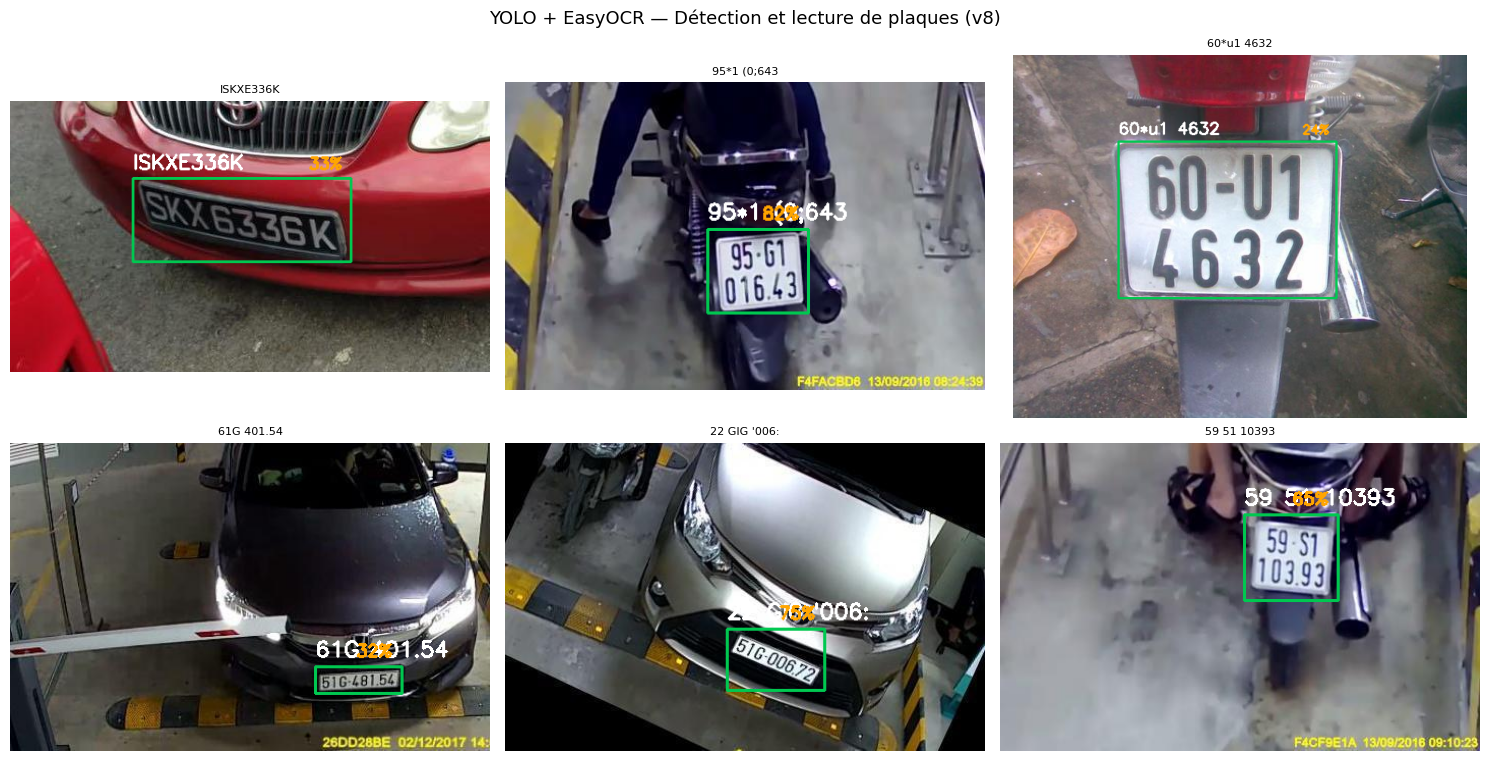

In [ ]:
# Cellule 8 — Détection + OCR sur images de test (v8)
import cv2
import matplotlib.pyplot as plt
import easyocr
import os
import re
import random
import numpy as np
from ultralytics import YOLO

# ─── Chargement modèle + OCR ─────────────────────────────────────────────────
MODEL_PATH = '/content/drive/MyDrive/plaque_voiture/entrainement_v1/weights/best.pt'
model  = YOLO(MODEL_PATH)
reader = easyocr.Reader(['vi'], gpu=True)


# ─── Helpers ──────────────────────────────────────────────────────────────────
def preprocess_plaque(crop_bgr):
    gray = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2GRAY)
    _, w = gray.shape
    scale = max(2, 150 // (w + 1))
    resized = cv2.resize(gray, None, fx=scale, fy=scale,
                         interpolation=cv2.INTER_CUBIC)

    h_denoise = 15 if w < 60 else 8
    denoised = cv2.fastNlMeansDenoising(resized, h=h_denoise)

    _, thresh = cv2.threshold(denoised, 0, 255,
                               cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if cv2.countNonZero(thresh) < thresh.size * 0.15:
        thresh = cv2.bitwise_not(thresh)
    return thresh


def ocr_plaque(thresh_img):
    resultats = reader.readtext(
        thresh_img,
        detail=1,
        contrast_ths=0.1,   # seuil de contraste plus bas → détecte mieux les zones peu contrastées
        adjust_contrast=10  # rehausse le contraste avant reconnaissance
    )
    if not resultats:
        return 'Non lisible', 0.0
    texte     = ' '.join([r[1] for r in resultats])
    confiance = resultats[0][2]
    return texte, confiance


def normaliser_ocr(texte):
    texte = texte.upper()
    texte = re.sub(r'\s+', '', texte)
    texte = re.sub(r'[^A-Z0-9\-.]', '', texte)
    return texte


def valider_plaque_viet(texte):
    clean = normaliser_ocr(texte)
    return len(re.sub(r'[^A-Z0-9]', '', clean)) >= 4


# ─── Pipeline principal ───────────────────────────────────────────────────────
TEST_IMG_DIR = '/content/dataset/test/images'
images      = [f for f in os.listdir(TEST_IMG_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]
echantillon = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, nom in enumerate(echantillon):
    img_path = os.path.join(TEST_IMG_DIR, nom)

    img     = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w    = img.shape[:2]

    results = model(img_path, conf=0.3, verbose=False)
    boxes   = results[0].boxes.xyxy.cpu().numpy()

    textes_trouves = []

    for box in boxes:
        x1, y1, x2, y2 = map(int, box)
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        if x2 <= x1 or y2 <= y1:
            continue

        plaque = img[y1:y2, x1:x2]
        thresh = preprocess_plaque(plaque)
        texte, confiance = ocr_plaque(thresh)

        texte_final = texte if valider_plaque_viet(texte) else 'Non lisible'
        textes_trouves.append(texte_final)

        couleur = (0, 200, 80) if texte_final != 'Non lisible' else (200, 80, 0)
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), couleur, 2)
        cv2.putText(img_rgb, texte_final, (x1, max(y1 - 10, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

        if texte_final != 'Non lisible':
            cv2.putText(img_rgb, f'{confiance:.0%}',
                        (x2 - 45, max(y1 - 10, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 165, 0), 2)

    titre = ' | '.join(t[:20] for t in textes_trouves) if textes_trouves else 'Aucune plaque'
    axes[i].imshow(img_rgb)
    axes[i].set_title(titre, fontsize=8)
    axes[i].axis('off')

plt.suptitle('YOLO + EasyOCR — Détection et lecture de plaques (v8)', fontsize=13)
plt.tight_layout()
plt.show()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.6 MB/s eta 0:00:00
Mounted at /content/drive
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Évaluation sur 1020 images de test...

Résultats :
  TP = 1014  |  FP = 11  |  FN = 71
  Précision : 98.9%
  Rappel    : 93.5%
  F1-Score  : 96.1%


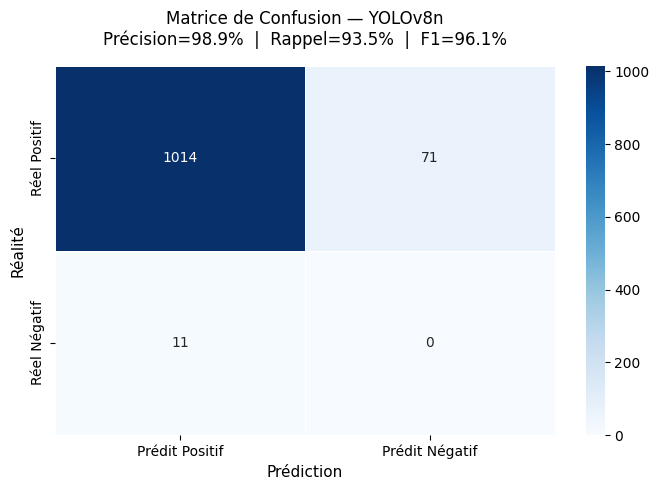

Matrice sauvegardée sur Drive ✅


In [ ]:
# Installations
!pip install ultralytics seaborn -q

# Remontage Drive
from google.colab import drive
drive.mount('/content/drive')

# Chemins
DATASET_PATH = '/content/drive/MyDrive/plaque_voiture/archive'

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

# ─── Chargement du modèle ────────────────────────────────────────────────────
MODEL_PATH = '/content/drive/MyDrive/plaque_voiture/entrainement_v1/weights/best.pt'
model = YOLO(MODEL_PATH)

# ─── Paramètres ──────────────────────────────────────────────────────────────
TEST_IMG_DIR = '/content/drive/MyDrive/plaque_voiture/archive/test/images'
TEST_LBL_DIR = '/content/drive/MyDrive/plaque_voiture/archive/test/labels'
CONF_SEUIL   = 0.5
IOU_SEUIL    = 0.5

# ─── Compteurs ───────────────────────────────────────────────────────────────
TP = 0
FP = 0
FN = 0

# ─── Fonction IoU ────────────────────────────────────────────────────────────
def calculer_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    aire1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    aire2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = aire1 + aire2 - intersection
    return intersection / union if union > 0 else 0

# ─── Boucle sur le dataset de test ───────────────────────────────────────────
images = [f for f in os.listdir(TEST_IMG_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]
print(f"Évaluation sur {len(images)} images de test...")

for nom in images:
    img_path = os.path.join(TEST_IMG_DIR, nom)
    lbl_path = os.path.join(TEST_LBL_DIR, nom.rsplit('.', 1)[0] + '.txt')

    img = cv2.imread(img_path)
    if img is None:
        continue
    h, w = img.shape[:2]

    # Boxes réelles
    gt_boxes = []
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for ligne in f.readlines():
                parts = ligne.strip().split()
                if len(parts) == 5:
                    _, cx, cy, bw, bh = map(float, parts)
                    x1 = int((cx - bw/2) * w)
                    y1 = int((cy - bh/2) * h)
                    x2 = int((cx + bw/2) * w)
                    y2 = int((cy + bh/2) * h)
                    gt_boxes.append([x1, y1, x2, y2])

    # Boxes prédites
    results    = model(img_path, conf=CONF_SEUIL, verbose=False)
    pred_boxes = results[0].boxes.xyxy.cpu().numpy().tolist()

    # Matching
    gt_matchees = [False] * len(gt_boxes)

    for j, pred in enumerate(pred_boxes):
        meilleur_iou = 0
        meilleur_idx = -1
        for k, gt in enumerate(gt_boxes):
            if gt_matchees[k]:
                continue
            iou = calculer_iou(pred, gt)
            if iou > meilleur_iou:
                meilleur_iou = iou
                meilleur_idx = k

        if meilleur_iou >= IOU_SEUIL and meilleur_idx >= 0:
            TP += 1
            gt_matchees[meilleur_idx] = True
        else:
            FP += 1

    FN += gt_matchees.count(False)

# ─── Métriques ───────────────────────────────────────────────────────────────
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
rappel    = TP / (TP + FN) if (TP + FN) > 0 else 0
f1        = 2 * precision * rappel / (precision + rappel) if (precision + rappel) > 0 else 0

print(f"\nRésultats :")
print(f"  TP = {TP}  |  FP = {FP}  |  FN = {FN}")
print(f"  Précision : {precision*100:.1f}%")
print(f"  Rappel    : {rappel*100:.1f}%")
print(f"  F1-Score  : {f1*100:.1f}%")

# ─── Matrice de confusion ─────────────────────────────────────────────────────
matrice = np.array([[TP, FN], [FP, 0]])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    matrice,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Prédit Positif', 'Prédit Négatif'],
    yticklabels=['Réel Positif',   'Réel Négatif'],
    linewidths=0.5,
    ax=ax
)
ax.set_title(
    f'Matrice de Confusion — YOLOv8n\n'
    f'Précision={precision:.1%}  |  Rappel={rappel:.1%}  |  F1={f1:.1%}',
    fontsize=12, pad=15
)
ax.set_ylabel('Réalité', fontsize=11)
ax.set_xlabel('Prédiction', fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/plaque_voiture/matrice_confusion.png', dpi=150)
plt.show()
print("Matrice sauvegardée sur Drive ✅")